In [1]:
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from scipy.stats import genextreme as gev

from unseen import fileio
from unseen import process_utils
from unseen import eva
from unseen import general_utils
from unseen import spatial_selection

In [2]:
var = 'pr'

## Read MSWEP data

[Multi-Source Weighted-Ensemble Precipitation (MSWEP)](https://www.gloh2o.org/): A merging of gauge, satellite and reanalysis data.  

In [4]:
mswep_file = '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/prJA_MSWEP_1979-2025_annual_central-pakistan.nc'
mswep_ds = fileio.open_dataset(mswep_file)
mswep_ds = mswep_ds.dropna("time")

mswep_years = mswep_ds["time"].dt.year.values
mswep_df = pd.DataFrame(index=mswep_years)
mswep_df[var] = mswep_ds[var].values

ranked_mswep_df = mswep_df.sort_values([var,], ascending=False)
ranked_mswep_df.head(n=5)

,pr
2022,437.725159
1994,222.350235
2003,188.172882
2010,181.506699
1992,170.816956


In [5]:
ranked_mswep_df.head(n=5) / 62

,pr
2022,7.060083
1994,3.586294
2003,3.035047
2010,2.927527
1992,2.755112


## Read CPC data

[CPC Global Unified Gauge-Based Analysis of Daily Precipitation](https://psl.noaa.gov/data/gridded/data.cpc.globalprecip.html): Gauge-based.

In [6]:
cpc_file = '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/prJA_CPC_1979-2025_annual_central-pakistan.nc'
cpc_ds = fileio.open_dataset(cpc_file)
cpc_ds = cpc_ds.dropna("time")

cpc_years = cpc_ds["time"].dt.year.values
cpc_df = pd.DataFrame(index=cpc_years)
cpc_df[var] = cpc_ds[var].values

ranked_cpc_df = cpc_df.sort_values([var,], ascending=False)
ranked_cpc_df.head(n=5) / 62

,pr
2022,8.364351
2024,3.672298
2020,3.439924
2006,2.119701
1994,2.071267


## Read ERA5 data

In [8]:
era_file = '/g/data/xv83/unseen-projects/outputs/wcrp-prJA/data/prJA_ERA5_1940-2025_annual_central-pakistan.nc'
era_ds = fileio.open_dataset(era_file)
era_ds = era_ds.dropna("time")

era_years = era_ds["time"].dt.year.values
era_df = pd.DataFrame(index=era_years)
era_df[var] = era_ds[var].values

ranked_era_df = era_df.sort_values([var,], ascending=False)
ranked_era_df.head(n=5) / 62

,pr
2022,6.536401
1956,4.799643
1953,4.721752
1994,4.532851
1959,3.439216


## Dataset comparison

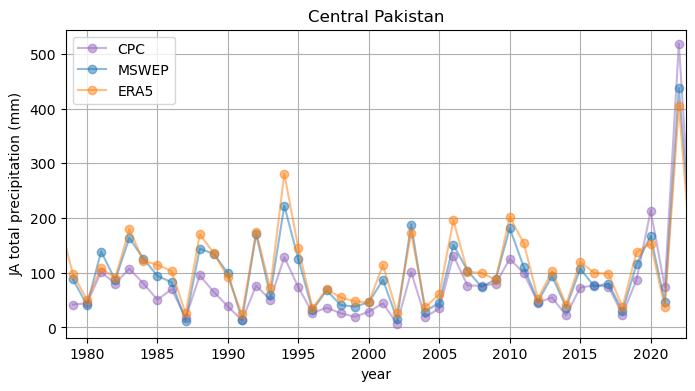

In [9]:
fig, ax = plt.subplots(figsize=[8, 4])
plt.plot(cpc_years, cpc_ds[var].values, marker='o', label='CPC', color='tab:purple', alpha=0.5)
plt.plot(mswep_years, mswep_ds[var].values, marker='o', label='MSWEP', color='tab:blue', alpha=0.5)
plt.plot(era_years, era_ds[var].values, marker='o', label='ERA5', color='tab:orange', alpha=0.5)
plt.xlim(1979 - 0.5, 2022 + 0.5)
plt.title('Central Pakistan')
plt.ylabel('JA total precipitation (mm)')
plt.xlabel('year')
plt.legend()
plt.grid()

In [10]:
mswep_2022_event = mswep_ds[var].sel(time=slice('2022-01-01', '2022-12-31')).values[0]
cpc_2022_event = cpc_ds[var].sel(time=slice('2022-01-01', '2022-12-31')).values[0]
era_2022_event = era_ds[var].sel(time=slice('2022-01-01', '2022-12-31')).values[0]

## Estimate the likelihood of the most extreme event

For this analysis we use all years from the observational dataset. That means the record event is included in the analysis (some studies would consider 2022 a trigger event and assess the period up to 2022).

In [70]:
def likelihood(data, event):
    """Calculate event likelihood"""

    nsamples = len(data)
    nexceedances = int(np.sum(data >= event))
    print(f'Exceednances: {nexceedances} in {nsamples} samples') 
    probability = nexceedances / nsamples
    return_period = 1. / probability
    percentile = (1 - probability) * 100
    print(f'{return_period:.0f} year return period')
    print(f'{percentile:.2f}% percentile')

In [71]:
likelihood(mswep_ds[var].values, mswep_2022_event)

Exceednances: 1 in 48 samples
48 year return period
97.92% percentile


In [72]:
likelihood(cpc_ds[var].values, cpc_2022_event)

Exceednances: 1 in 47 samples
47 year return period
97.87% percentile


In [73]:
likelihood(era_ds[var].values, era_2022_event)

Exceednances: 1 in 86 samples
86 year return period
98.84% percentile


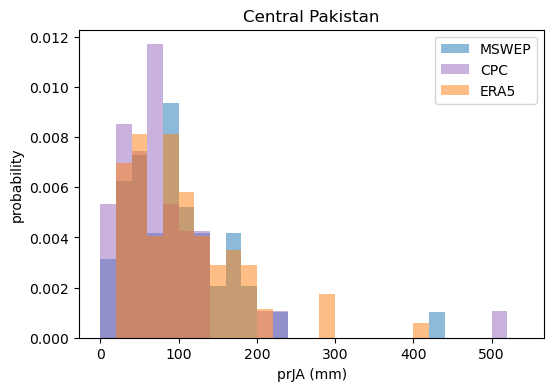

In [51]:
fig, ax = plt.subplots(figsize=[6, 4])
xvals = np.arange(0, 550, 20)
bins = np.arange(0, 550, 20)

mswep_ds[var].plot.hist(bins=bins, density=True, color='tab:blue', label='MSWEP', alpha=0.5)

cpc_ds[var].plot.hist(bins=bins, density=True, color='tab:purple', label='CPC', alpha=0.5)

era_ds[var].plot.hist(bins=bins, density=True, color='tab:orange', label='ERA5', alpha=0.5)

plt.xlabel('prJA (mm)')
plt.ylabel('probability')
plt.title('Central Pakistan')
plt.legend()
plt.show()